# 02 · Validación cruzada anidada y elección del modelo

**Pregunta.** ¿Cuánto discrimina cada familia de modelos (regresión logística L2, Random
Forest, Gradient Boosting), ya ajustada y con una sola configuración para los tres cortes, en
un periodo que no ha visto? Los árboles ajustados en cada pliegue dan además la importancia de
las variables que usa la selección del notebook 03.

**Protocolo** (D4, D5, E10). `comun.nested_cv_joint`: bucle externo dejando fuera 2013B, 2013J
y 2014B por turnos; bucle interno con los otros dos periodos (dos pliegues), donde se elige la
combinación de `comun.GRIDS` con mayor ROC-AUC media **sobre los tres cortes**; con ella se
reajusta cada corte y se predice el periodo externo. Aquí la logística usa todas las
candidatas; con su selección de variables, y la elección del modelo (D9), en el notebook 03.

**Regla de decisión** (D5, rejilla). Si el valor elegido de un hiperparámetro numérico cae en un
extremo de la rejilla en al menos 2 de los 3 pliegues externos, se amplía en esa dirección y
se repite (E3 sigue vigente para los bordes compensados del GB).

Solo periodos de entrenamiento (2013B, 2013J, 2014B).

In [1]:
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import comun as c  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import joblib  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402

c.thesis_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
data = {cut: c.load_train(cut) for cut in c.CUTS}
MODELS = list(c.GRIDS)

## 0. Esquema de la validación anidada (figura de método, sin datos)

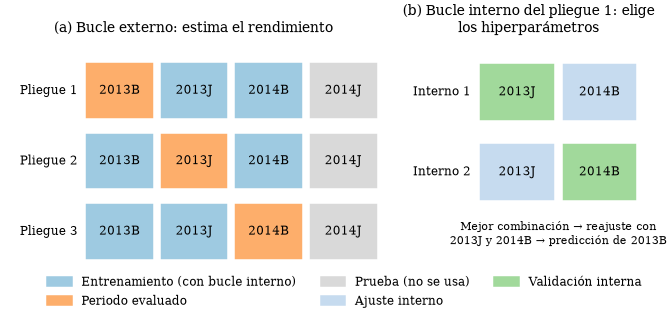

In [2]:
from matplotlib.patches import Patch, Rectangle  # noqa: E402

COL = {"train": "#9ecae1", "eval": "#fdae6b", "test": "#d9d9d9", "inner_fit": "#c6dbef", "inner_val": "#a1d99b"}
fig, (axa, axb) = plt.subplots(1, 2, figsize=(6.5, 2.7), gridspec_kw={"width_ratios": [4, 2.6]})
periods = c.TRAIN_PERIODS + [c.TEST_PERIOD]
for i, out in enumerate(c.TRAIN_PERIODS):
    y = 2 - i
    for j, p in enumerate(periods):
        kind = "test" if p == c.TEST_PERIOD else "eval" if p == out else "train"
        axa.add_patch(Rectangle((j, y + 0.1), 0.92, 0.8, facecolor=COL[kind], edgecolor="white"))
        axa.text(j + 0.46, y + 0.5, p, ha="center", va="center", fontsize=8)
    axa.text(-0.1, y + 0.5, f"Pliegue {i + 1}", ha="right", va="center", fontsize=8)
axa.set_xlim(-1.1, 4)
axa.set_ylim(0, 3.2)
axa.set_title("(a) Bucle externo: estima el rendimiento", fontsize=9)
inner = ["2013J", "2014B"]
for i, val in enumerate(inner):
    y = 1.6 - 1.1 * i
    for j, p in enumerate(inner):
        axb.add_patch(Rectangle((j, y + 0.1), 0.92, 0.8, facecolor=COL["inner_val" if p == val else "inner_fit"], edgecolor="white"))
        axb.text(j + 0.46, y + 0.5, p, ha="center", va="center", fontsize=8)
    axb.text(-0.1, y + 0.5, f"Interno {i + 1}", ha="right", va="center", fontsize=8)
axb.text(0.96, 0.15, "Mejor combinación → reajuste con\n2013J y 2014B → predicción de 2013B", ha="center", va="center", fontsize=7.5)
axb.set_xlim(-0.9, 2.1)
axb.set_ylim(-0.3, 2.8)
axb.set_title("(b) Bucle interno del pliegue 1: elige\nlos hiperparámetros", fontsize=9)
for ax in (axa, axb):
    ax.axis("off")
handles = [Patch(color=COL["train"], label="Entrenamiento (con bucle interno)"), Patch(color=COL["eval"], label="Periodo evaluado"),
           Patch(color=COL["test"], label="Prueba (no se usa)"), Patch(color=COL["inner_fit"], label="Ajuste interno"),
           Patch(color=COL["inner_val"], label="Validación interna")]
fig.legend(handles=handles, ncols=3, loc="lower center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
fig.tight_layout()
c.save_figure(fig, "esquema_validacion_anidada")
plt.show()

## 1. Validación anidada con una configuración común a los cortes

Las búsquedas internas por corte del RF y del GB son las de la primera ronda (E2) y se
reutilizan; aquí solo se promedian sobre los cortes y se reajusta. Resultados en
`artifacts/nested_joint_<modelo>.joblib`.

In [3]:
res = {}
for m in MODELS:
    t = time.time()
    res[m] = c.nested_cv_joint(m, data)
    print(f"{m:>3} · {time.time() - t:6.0f} s", flush=True)

 lr ·      0 s


 rf ·      0 s


 gb ·      0 s


## 2. ROC-AUC en el periodo dejado fuera

In [4]:
def baseline_fold_aucs(d):
    return {p: roc_auc_score(g[c.TARGET], c.baseline_score(g)) for p, g in d.groupby("code_presentation")}


rows = []
for cut in c.CUTS:
    for m in MODELS:
        folds = res[m][cut]["folds"]
        vals = [f["auc_val"] for f in folds]
        rows.append({"corte": cut, "modelo": m, **{f["period"]: f["auc_val"] for f in folds},
                     "media": np.mean(vals), "desv.": np.std(vals, ddof=1),
                     "entrenamiento": np.mean([f["auc_train"] for f in folds])})
    b = baseline_fold_aucs(data[cut])
    rows.append({"corte": cut, "modelo": "nota", **b, "media": np.mean(list(b.values())),
                 "desv.": np.std(list(b.values()), ddof=1), "entrenamiento": np.nan})
table = pd.DataFrame(rows).set_index(["corte", "modelo"])
table

2013B  2013J  2014B  media  desv.  entrenamiento
corte modelo                                                  
first lr      0.832  0.818  0.815  0.822  0.009          0.824
      rf      0.832  0.818  0.818  0.823  0.008          0.857
      gb      0.834  0.816  0.817  0.823  0.010          0.836
      nota    0.813  0.797  0.794  0.801  0.010            NaN
mid   lr      0.917  0.912  0.894  0.908  0.012          0.912
      rf      0.921  0.914  0.900  0.912  0.011          0.931
      gb      0.921  0.914  0.902  0.912  0.009          0.922
      nota    0.910  0.897  0.872  0.893  0.019            NaN
last  lr      0.943  0.944  0.932  0.940  0.007          0.946
      rf      0.946  0.947  0.943  0.945  0.002          0.960
      gb      0.946  0.947  0.943  0.945  0.002          0.954
      nota    0.938  0.939  0.912  0.929  0.015            NaN

## 3. Configuración elegida en cada pliegue externo (común a los cortes) y extremos (D5)

In [5]:
chosen = pd.DataFrame([{"modelo": m, "periodo fuera": f["period"], **f["params"]}
                       for m in MODELS for f in res[m]["first"]["folds"]])
chosen

,modelo,periodo fuera,logisticregression__C,min_samples_leaf,max_features,learning_rate,max_depth,n_estimators
0,lr,2013B,0.1,NaN,NaN,NaN,NaN,NaN
1,lr,2013J,0.1,NaN,NaN,NaN,NaN,NaN
2,lr,2014B,0.3,NaN,NaN,NaN,NaN,NaN
3,rf,2013B,NaN,50.0,sqrt,NaN,NaN,NaN
4,rf,2013J,NaN,50.0,sqrt,NaN,NaN,NaN
5,rf,2014B,NaN,50.0,sqrt,NaN,NaN,NaN
6,gb,2013B,NaN,NaN,NaN,0.02,2.0,300.0
7,gb,2013J,NaN,NaN,NaN,0.05,3.0,100.0
8,gb,2014B,NaN,NaN,NaN,0.02,2.0,300.0


In [6]:
edges = []
for m, g in chosen.groupby("modelo", sort=False):
    for k, values in c.GRIDS[m].items():
        if not all(isinstance(v, (int, float)) for v in values):
            continue
        lo, hi = min(values), max(values)
        edges.append({"modelo": m, "hiperparámetro": k,
                      "en el mínimo": int((g[k] == lo).sum()), "en el máximo": int((g[k] == hi).sum())})
edges = pd.DataFrame(edges)
edges["ampliar"] = np.where(edges["en el mínimo"] >= 2, "hacia abajo",
                            np.where(edges["en el máximo"] >= 2, "hacia arriba", ""))
edges

,modelo,hiperparámetro,en el mínimo,en el máximo,ampliar
0,lr,logisticregression__C,0,0,
1,rf,min_samples_leaf,0,0,
2,gb,learning_rate,2,0,hacia abajo
3,gb,max_depth,0,0,
4,gb,n_estimators,0,2,hacia arriba


In [7]:
# Cuánto se pierde en cada corte por usar la configuración común en vez de la mejor de ese corte
# (búsquedas internas, media sobre pliegues externos)
loss = []
for m in MODELS:
    for cut in c.CUTS:
        diffs = []
        for p in c.TRAIN_PERIODS:
            t = joblib.load(c.ARTIFACTS / f"inner_{m}_{cut}_{p}.joblib")
            common = res[m]["inner"][p].loc[0, "params"]
            diffs.append(t["auc"].max() - t.loc[t["params"].map(c._key) == c._key(common), "auc"].iloc[0])
        loss.append({"modelo": m, "corte": cut, "pérdida media en la búsqueda interna": np.mean(diffs)})
pd.DataFrame(loss).pivot(index="modelo", columns="corte", values="pérdida media en la búsqueda interna")[c.CUTS]

corte,first,mid,last
modelo,,,
gb,9.153e-04,6.353e-05,3.811e-04
lr,9.978e-06,2.181e-05,0.000e+00
rf,1.159e-04,2.627e-05,2.944e-04


## 4. Sobreajuste y regularización

Diferencia entre la ROC-AUC en el entrenamiento del pliegue y en el periodo dejado fuera, y
ROC-AUC de la validación interna del RF según el tamaño mínimo de hoja (media sobre cortes).

In [8]:
gap = (table["entrenamiento"] - table["media"]).unstack("modelo")[MODELS]
gap

modelo,lr,rf,gb
corte,,,
first,0.002,0.034,0.014
last,0.006,0.015,0.009
mid,0.004,0.019,0.010


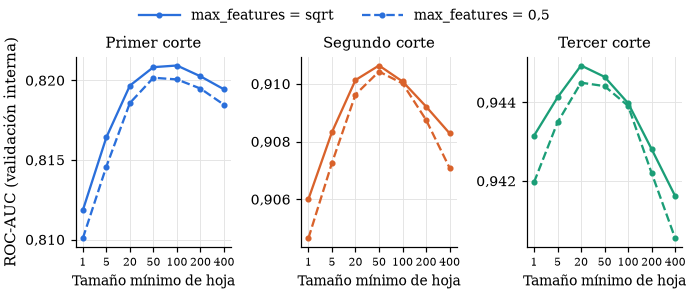

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.6), sharey=False)
for ax, cut in zip(axes, c.CUTS):
    for mf, ls in [("sqrt", "-"), (0.5, "--")]:
        curves = []
        for p in c.TRAIN_PERIODS:
            inner = joblib.load(c.ARTIFACTS / f"inner_rf_{cut}_{p}.joblib")
            sel = inner[inner["params"].map(lambda q: q["max_features"] == mf)]
            curves.append(sel.set_index(sel["params"].map(lambda q: q["min_samples_leaf"]))["auc"].sort_index())
        curve = pd.concat(curves, axis=1).mean(axis=1)
        ax.plot(range(len(curve)), curve.values, ls, marker="o", ms=3, color=c.CUT_COLORS[cut],
                label=f"max_features = {mf if mf == 'sqrt' else c.comma(mf, 1)}")
    leaves = c.GRIDS["rf"]["min_samples_leaf"]
    ax.set_xticks(range(len(leaves)), [str(v) for v in leaves], fontsize=7)
    ax.set_xlabel("Tamaño mínimo de hoja", fontsize=9)
    ax.set_title(c.CUT_NAMES[cut])
    ax.yaxis.set_major_locator(plt.MaxNLocator(4, steps=[1, 2, 5, 10]))
    c.comma_axis(ax, "y", 3)
axes[0].set_ylabel("ROC-AUC (validación interna)")
handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, ncols=2, loc="upper center", bbox_to_anchor=(0.5, 1.08), handlelength=3)
fig.tight_layout()
c.save_figure(fig, "regularizacion_rf")
plt.show()

In [10]:
c.save_json({"table": table.reset_index().to_dict("records"), "chosen": chosen.to_dict("records"),
             "edges": edges.to_dict("records")}, c.ARTIFACTS / "02_validacion.json")

## Conclusiones

- **Configuración común a los cortes** (E10, E11): logística C = 0,1–0,3; RF con hojas de 50 y
  `max_features` = √p en los tres pliegues; GB (0,02; 2; 300) en dos y (0,05; 3; 100) en uno.
  Respecto a la mejor configuración de cada corte, se pierde menos de 0,001 de ROC-AUC interna.
- **Grilla.** Solo el GB toca bordes (tasa mínima y número de árboles máximo, que se compensan):
  E3, no se amplía. Logística y RF tienen el óptimo dentro.
- **Sobreajuste tratado**: la diferencia entre entrenamiento y validación es ≤ 0,034 (RF, primer
  corte), ≤ 0,014 (GB) y ≤ 0,006 (logística); el RF rinde peor con hojas de 1 estudiante.
- ROC-AUC externa: los tres modelos equivalentes en el primer corte (0,822–0,823); RF y GB algo
  por encima de la logística en el segundo y el tercero. La elección (D9) se hace en el
  notebook 03, con la logística ya con su selección de variables.